In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

team_matches = pd.read_csv("../data/processed/team_matches.csv")
match_pairs = pd.read_csv("../data/processed/match_pairs.csv")

rate_cols = ["ace_rate", "serve_error_rate",
             "positive_reception_rate", "perfect_reception_rate", "reception_error_rate",
             "attack_kill_rate", "attack_error_rate", "attack_blocked_rate", "attack_efficiency",
             "blocks_per_set"]

team_matches["result"] = team_matches["win"].map({1: "Winner", 0: "Loser"})
team_matches.groupby("result")[rate_cols].mean().T


result,Loser,Winner
ace_rate,0.062308,0.080894
serve_error_rate,0.152860,0.129474
positive_reception_rate,0.436426,0.479758
perfect_reception_rate,0.209503,0.241615
reception_error_rate,0.100401,0.079425
attack_kill_rate,0.377754,0.460530
attack_error_rate,0.095678,0.074910
attack_blocked_rate,0.094702,0.068001
attack_efficiency,0.187374,0.317619
blocks_per_set,1.931493,2.695980


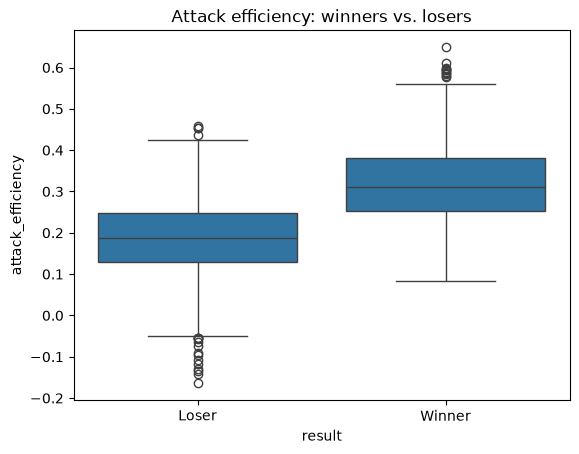

In [2]:
sns.boxplot(data=team_matches, x="result", y="attack_efficiency")
plt.title("Attack efficiency: winners vs. losers")
plt.show()

## Attack efficiency
- Median attack efficiency is about 0.31 for winners and 0.19 for losers.
- The boxes barely overlap, so attack efficiency separates winners and losers well.
- The whiskers overlap: a strong attack alone does not guarantee a win.
- Some losers have negative efficiency (more errors than points).

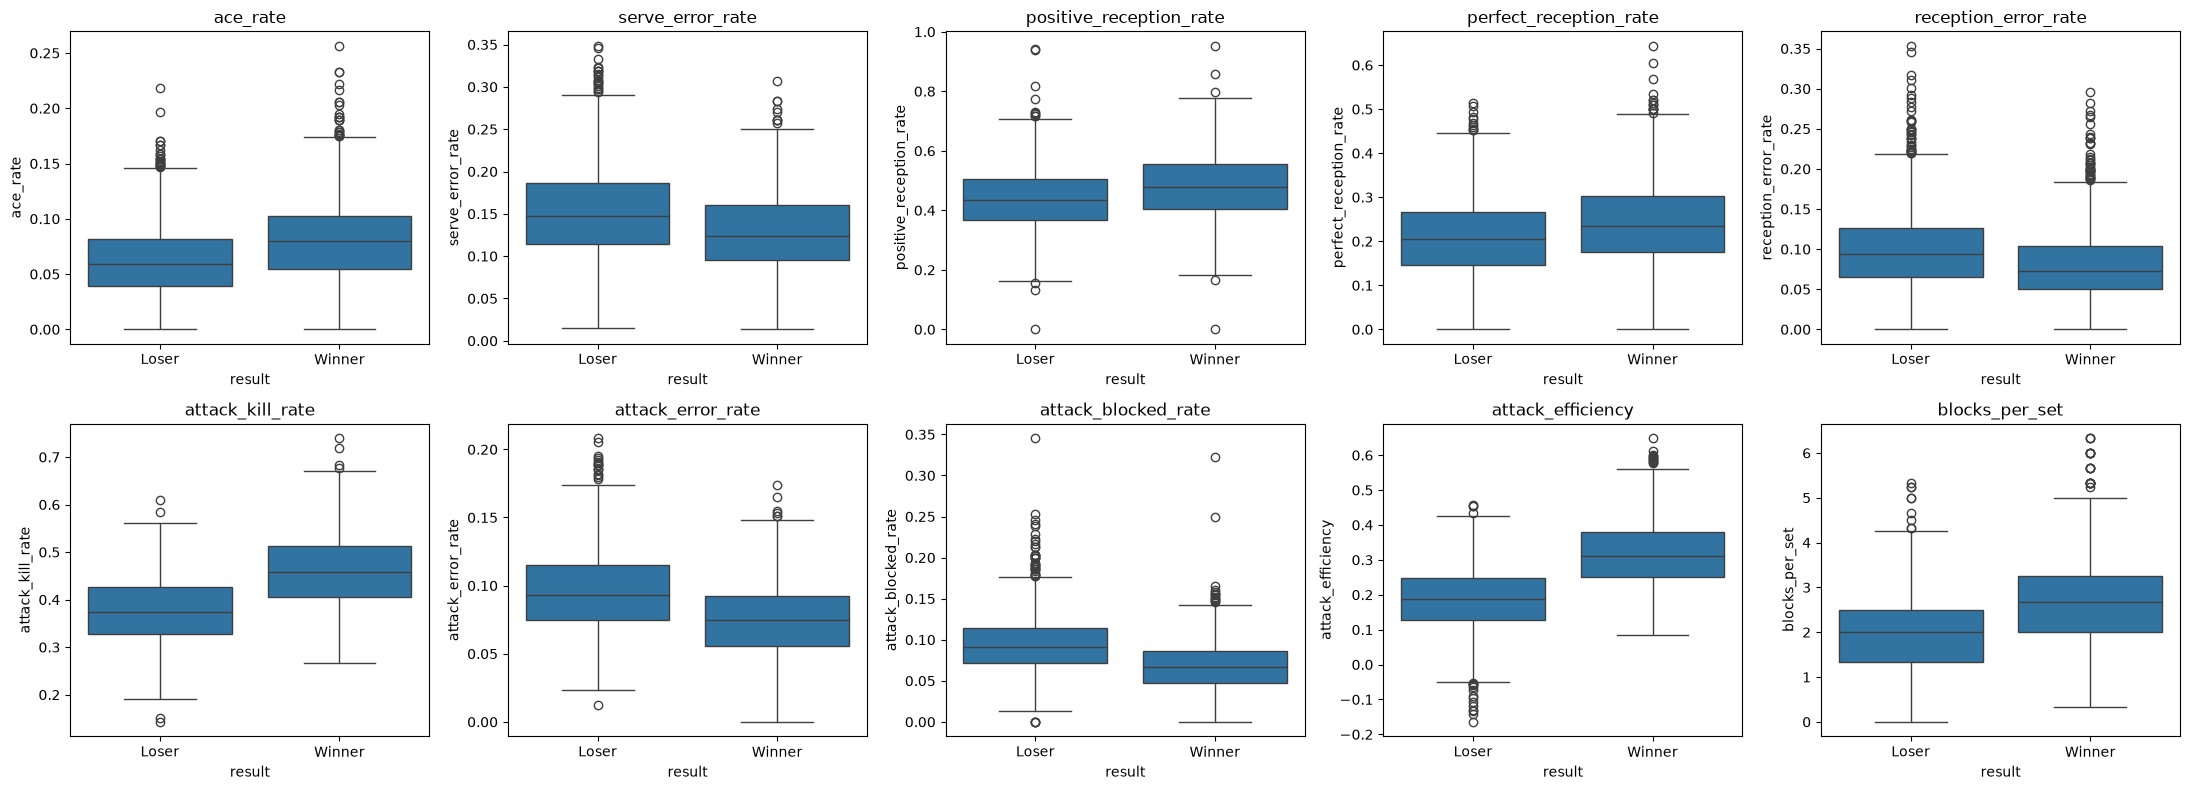

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))

for ax, col in zip(axes.flat, rate_cols):
    sns.boxplot(data=team_matches, x="result", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## All skill rates
- Winners are better in every skill (higher success rates, lower error rates).
- Attacking (kill rate, efficiency) shows the clearest separation.
- Blocking and blocked attacks also differ clearly.
- Serving and receiving boxes overlap strongly, so the differences are smaller.

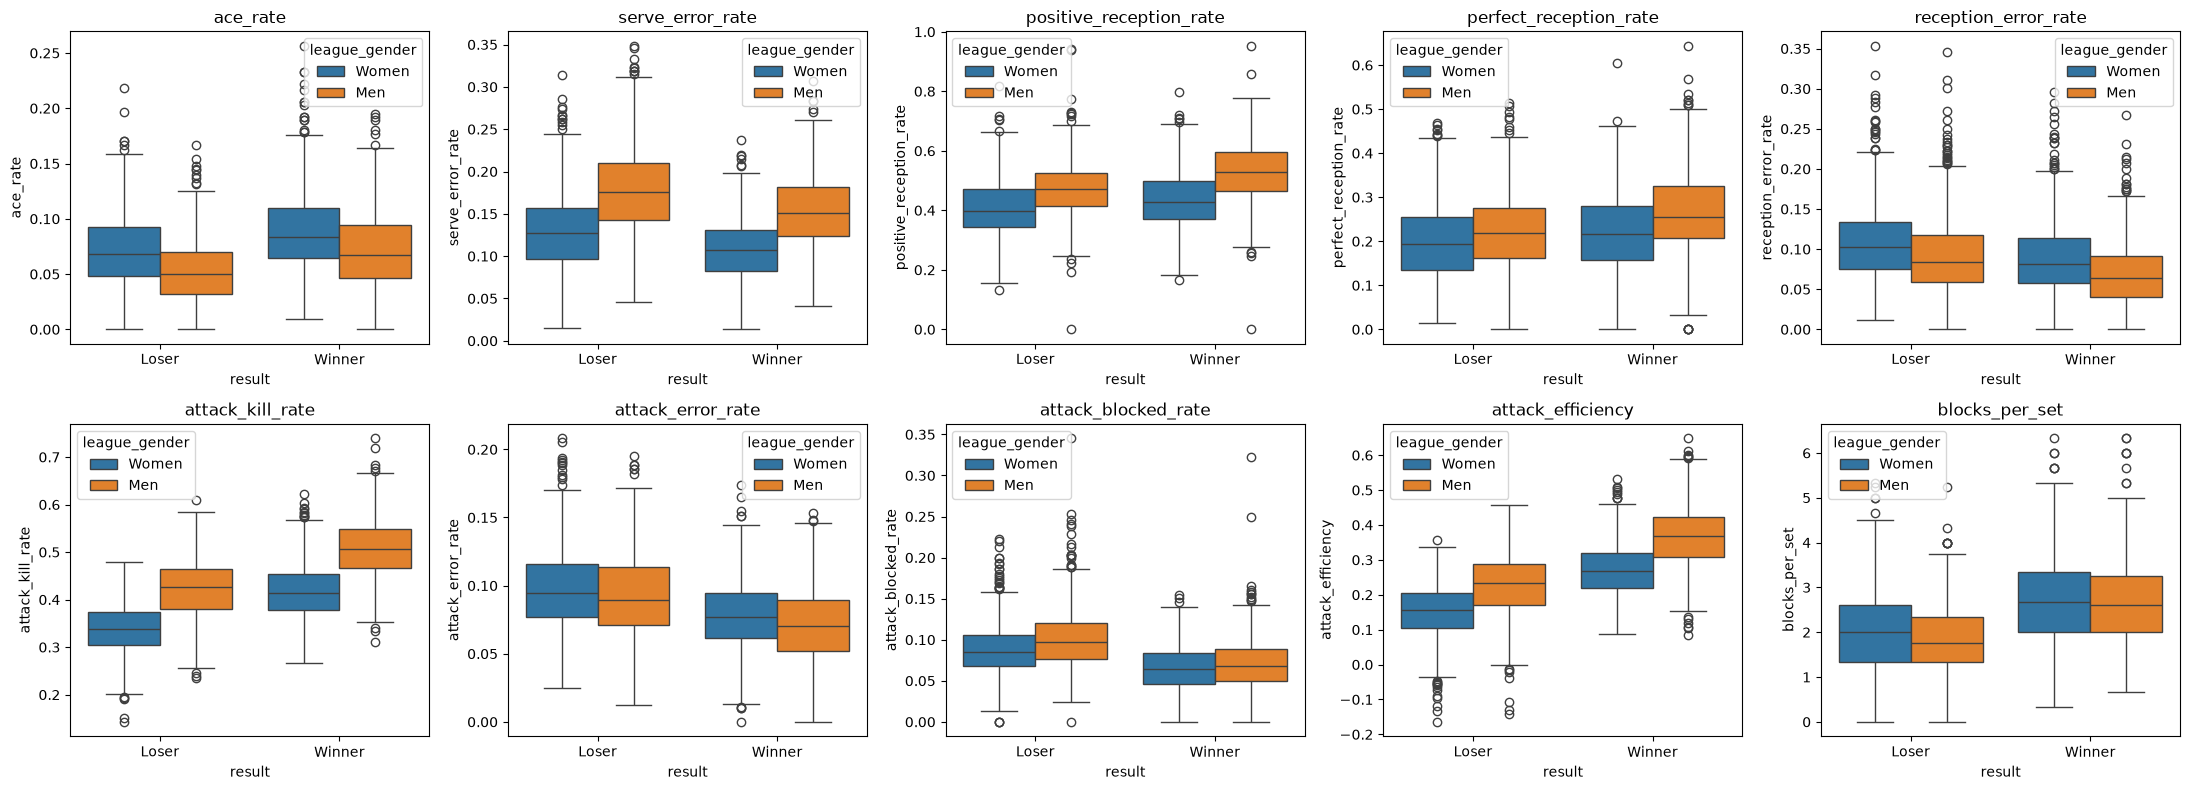

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))

for ax, col in zip(axes.flat, rate_cols):
    sns.boxplot(data=team_matches, x="result", y=col, ax=ax, hue="league_gender")
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Skill rates by league
- The leagues play differently: men have higher attack and reception rates but more serve errors; women have more aces.
- Blocks per set are similar in both leagues.
- The winner–loser gap looks similar in both leagues; exact numbers follow below.

In [5]:
diff_cols = [col + "_diff" for col in rate_cols]
match_pairs.groupby("league_gender")[diff_cols].mean().T

league_gender,Men,Women
ace_rate_diff,0.019310,0.017942
serve_error_rate_diff,-0.024607,-0.022300
positive_reception_rate_diff,0.059053,0.029332
perfect_reception_rate_diff,0.044539,0.021045
reception_error_rate_diff,-0.023602,-0.018638
attack_kill_rate_diff,0.087354,0.078699
attack_error_rate_diff,-0.021716,-0.019924
attack_blocked_rate_diff,-0.031256,-0.022644
attack_efficiency_diff,0.140326,0.121267
blocks_per_set_diff,0.829024,0.707017


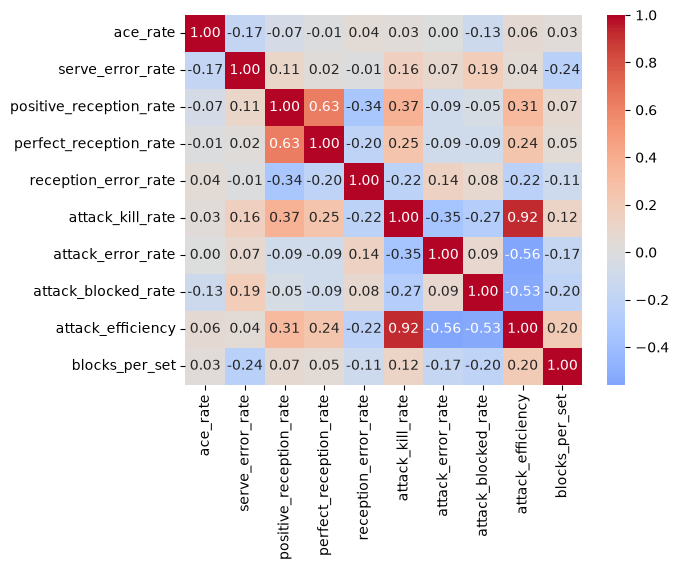

In [6]:
sns.heatmap(team_matches[rate_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

## Correlations between skill rates (both leagues)
- Attack kill rate and attack efficiency are almost identical (r = 0.92), because efficiency is calculated from kills, errors and blocked attacks.
- Positive and perfect reception are strongly related (r = 0.63).
- Positive reception and attack kill rate are moderately related (r = 0.37): a good reception makes a good attack easier.
- Serving is almost unrelated to the other skills.
- Highly correlated features should not all be used together in the ML model.

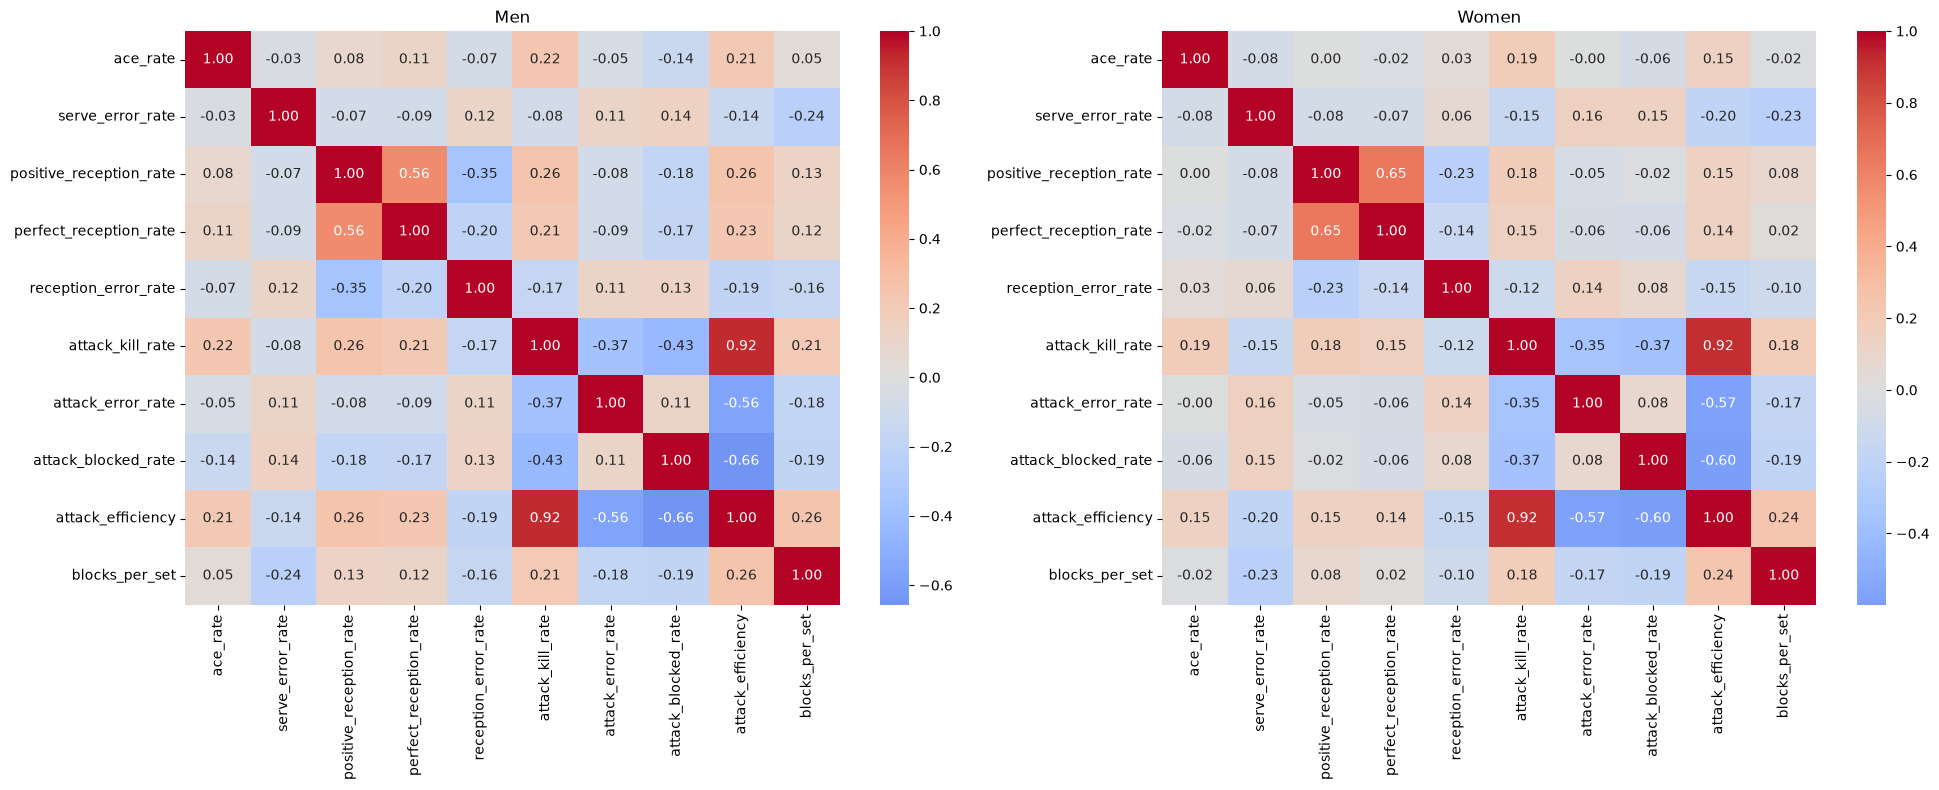

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

for ax, gender in zip(axes, ["Men", "Women"]):
    league = team_matches[team_matches["league_gender"] == gender]
    sns.heatmap(league[rate_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
    ax.set_title(gender)

plt.tight_layout()
plt.show()

## Correlations by league
- Serve errors and attack kill rate: r = 0.16 when both leagues are combined, but negative within each league (men −0.08, women −0.15).
- The positive correlation only appears because men have both more serve errors and higher kill rates. Mixing the leagues creates a misleading relationship.
- Reception and attack are more closely related in the men's league (r = 0.26) than in the women's league (r = 0.18), which fits the larger reception gap for men.
- Conclusion: the leagues should be analyzed separately.